In [1]:
# Import libraries
import pandas as pd
import numpy as np
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import cross_val_score

In [2]:
# Load Dataset
wine = load_wine()


In [3]:
# Convert to DataFrame including features
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


In [5]:
# Add Output Column ✅
df['Wine_Type'] = wine.target

In [6]:
df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Wine_Type
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,2


In [7]:
df.shape

(178, 14)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  Wine_

In [10]:
X = wine.data
y = wine.target

In [11]:
# Feature Scaling (important for KNN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# K selection (Hyperparameter tuning)
To find the best value of K (number of neighbors) for KNN

In [12]:
# Try different K values
k_values = range(1, 15)
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_scaled, y, cv=5)
    cv_scores.append(scores.mean())

**k_values = range(1, 15)**

This creates a list of k values from 1 to 14.

**cv_scores = []**

An empty list to store the average accuracy for each k.

**knn = KNeighborsClassifier(n_neighbors=k)**

This initializes the KNN model with the chosen k.


**scores = cross_val_score(knn, X_scaled, y, cv=5)**

This line does the 5-Fold Cross Validation

What happens inside:

The dataset (X_scaled, y) is split into 5 equal parts (folds).

The algorithm repeats training 5 times, each time:

Uses 4 folds for training (80%)

Uses 1 fold for testing (20%)

Each time it calculates the accuracy of the model on the test fold.

So you get 5 accuracy values → like [0.94, 0.96, 0.97, 0.95, 0.96]


Your dataset is split into 5 folds.

For each iteration:

4 folds (80%) are used to train the KNN model.

1 fold (20%) is used to test it.

The model makes predictions on that test fold.

Accuracy = number of correct predictions ÷ number of test samples.

scikit-learn stores that accuracy for this fold.

In [13]:
# Create a table for better visualization
results = pd.DataFrame({'K Value': k_values, 'Mean CV Accuracy': cv_scores})

In [14]:
# Display the results
print("📊 Cross-Validation Scores for Different K Values:")
print(results)

📊 Cross-Validation Scores for Different K Values:
    K Value  Mean CV Accuracy
0         1          0.949524
1         2          0.938413
2         3          0.943968
3         4          0.938413
4         5          0.955079
5         6          0.949524
6         7          0.966508
7         8          0.966508
8         9          0.949683
9        10          0.955238
10       11          0.955238
11       12          0.955238
12       13          0.955238
13       14          0.955238


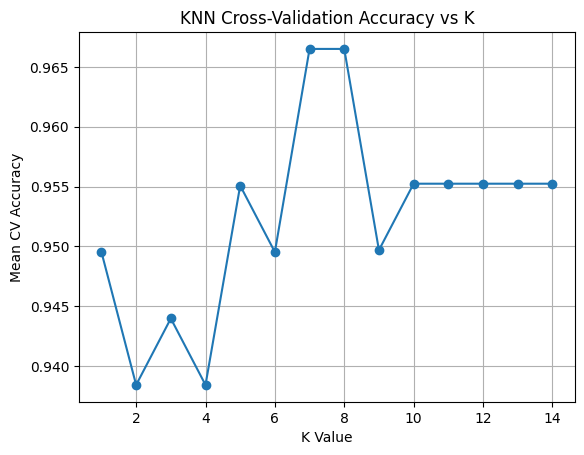

In [15]:
import matplotlib.pyplot as plt

plt.plot(k_values, cv_scores, marker='o')
plt.title("KNN Cross-Validation Accuracy vs K")
plt.xlabel("K Value")
plt.ylabel("Mean CV Accuracy")
plt.grid(True)
plt.show()

In [16]:
# Find best K
best_k = k_values[np.argmax(cv_scores)]
print(f"🏆 Best K Value: {best_k}")
print(f"✅ Highest Mean CV Accuracy: {max(cv_scores):.3f}")

🏆 Best K Value: 7
✅ Highest Mean CV Accuracy: 0.967


In [17]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

In [18]:
# KNN Model
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(X_train, y_train)


,n_neighbors,7
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [19]:
## Train using best K
#final_knn = KNeighborsClassifier(n_neighbors=int(best_k['K Value']))
#final_knn.fit(X_train, y_train)


n_neighbors

Most important hyperparameter

Controls how many neighbors are considered while predicting

The model finds the 7 nearest points in the training dataset (based on distance).

It checks which class is the majority among those 7.

That class becomes the prediction.

In [20]:
# Predict
y_pred = knn.predict(X_test)

In [21]:
# Evaluate
print("Accuracy of KNN:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy of KNN: 0.9629629629629629

Classification Report:
               precision    recall  f1-score   support

           0       0.95      1.00      0.97        19
           1       1.00      0.90      0.95        21
           2       0.93      1.00      0.97        14

    accuracy                           0.96        54
   macro avg       0.96      0.97      0.96        54
weighted avg       0.97      0.96      0.96        54



In [22]:
# Example prediction
sample = X_scaled[10].reshape(1, -1)
pred = knn.predict(sample)
print("Predicted Wine Type:", wine.target_names[pred][0])

Predicted Wine Type: class_0


X_scaled[10]	Takes the 11th row from the scaled dataset X_scaled (index starts at 0)

.reshape(1, -1)	Converts that 1-D array into a 2-D shape (1 row, all features) because scikit-learn requires 2D input while predicting